# Clasificación de noticias AG News con PyTorch

## Objetivo

Construir un pipeline de entrenamiento y validación en PyTorch
para clasificar noticias en cuatro categorías: Internacional,
Deportes, Negocios y Ciencia/Tecnología.

En esta primera etapa utilizamos un clasificador sencillo y
evaluamos su aprendizaje mediante la pérdida y la exactitud.
El mismo corpus se utilizará en las siguientes entregas de NLP.

## 1. Carga del dataset

Cargamos las noticias desde el repositorio público de GitHub.
El archivo de entrenamiento se dividirá en entrenamiento y
validación. El archivo de prueba se reserva para la evaluación final.

In [1]:
import pandas as pd

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "martingnegro/ag-news-classification-pytorch/main/data/"
)

#Cargo los datos disponibles para entrenamiento y validación.
train_df = pd.read_csv(BASE_URL + "ag_news_train.csv")

#Compruebo las columnas y las etiquetas.
EXPECTED_COLUMNS = ["Class Index", "Title", "Description"]

assert train_df.columns.tolist() == EXPECTED_COLUMNS, (
    "Las columnas no coinciden con la estructura esperada."
)
assert train_df["Class Index"].isin([1, 2, 3, 4]).all(), (
    "Hay etiquetas vacías o fuera de las cuatro categorías."
)
assert train_df[EXPECTED_COLUMNS].notna().all().all(), (
    "Hay valores faltantes que debemos revisar."
)

CLASS_NAMES = {
    1: "Internacional",
    2: "Deportes",
    3: "Negocios",
    4: "Ciencia/Tecnología",
}

print(f"Registros disponibles: {len(train_df):,}")
print(f"Valores faltantes: {train_df.isna().sum().sum()}")

distribution = (
    train_df["Class Index"]
    .value_counts()
    .sort_index()
    .rename_axis("Etiqueta")
    .reset_index(name="Noticias")
)
distribution["Categoría"] = distribution["Etiqueta"].map(CLASS_NAMES)

display(distribution[["Etiqueta", "Categoría", "Noticias"]])
display(train_df.head())

Registros disponibles: 120,000
Valores faltantes: 0


,Etiqueta,Categoría,Noticias
0,1,Internacional,30000
1,2,Deportes,30000
2,3,Negocios,30000
3,4,Ciencia/Tecnología,30000


,Class Index,Title,Description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."


## 2. Configuración del entorno

Utilizamos PyTorch y fijamos semillas para favorecer la reproducibilidad.
Seleccionamos automáticamente el dispositivo disponible: CUDA, MPS o CPU.

In [2]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

SEED = 42

#Fijo las semillas de aleatoriedad.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

#Configuro cuDNN para favorecer la reproducibilidad.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

#Selecciono el dispositivo disponible.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Versión de PyTorch: {torch.__version__}")
print(f"Dispositivo seleccionado: {device}")
print(f"Semilla utilizada: {SEED}")

Versión de PyTorch: 2.11.0+cpu
Dispositivo seleccionado: cpu
Semilla utilizada: 42


## 3. Separación de entrenamiento y validación

Unimos el título y la descripción de cada noticia. Dividimos el archivo
de entrenamiento en 70 % para entrenar y 30 % para validar, manteniendo
la proporción de categorías.

Convertimos las etiquetas de 1–4 a 0–3 para utilizarlas con PyTorch.
El archivo de prueba permanece reservado.

In [3]:
from sklearn.model_selection import train_test_split

#Uno el título y la descripción.
texts = (
    train_df["Title"].str.strip()
    + " "
    + train_df["Description"].str.strip()
)

#Convierto las etiquetas al rango 0–3.
labels = train_df["Class Index"].to_numpy(dtype=np.int64) - 1

#Divido los índices para conservar la referencia de cada noticia.
train_indices, val_indices = train_test_split(
    np.arange(len(train_df)),
    test_size=0.30,
    random_state=SEED,
    stratify=labels,
)

train_texts = texts.iloc[train_indices].reset_index(drop=True)
val_texts = texts.iloc[val_indices].reset_index(drop=True)

y_train = labels[train_indices]
y_val = labels[val_indices]

#Compruebo que ninguna fila se use en ambos conjuntos.
assert set(train_indices).isdisjoint(set(val_indices))

distribution = pd.DataFrame({
    "Etiqueta del modelo": range(4),
    "Categoría": [CLASS_NAMES[i] for i in range(1, 5)],
    "Entrenamiento": np.bincount(y_train, minlength=4),
    "Validación": np.bincount(y_val, minlength=4),
})

print(f"Noticias de entrenamiento: {len(train_texts):,}")
print(f"Noticias de validación: {len(val_texts):,}")

display(distribution)

Noticias de entrenamiento: 84,000
Noticias de validación: 36,000


,Etiqueta del modelo,Categoría,Entrenamiento,Validación
0,0,Internacional,21000,9000
1,1,Deportes,21000,9000
2,2,Negocios,21000,9000
3,3,Ciencia/Tecnología,21000,9000


## 4. Representación numérica del texto

Representamos cada noticia mediante la presencia o ausencia de palabras,
con un vocabulario de hasta 5.000 términos aprendido únicamente del
conjunto de entrenamiento.

Aplicamos el mismo vocabulario a validación. Conservamos las matrices
en formato disperso para reducir el uso de memoria.

In [4]:
from sklearn.feature_extraction.text import CountVectorizer

MAX_FEATURES = 5000

#Represento la presencia de palabras con valores 0 y 1.
vectorizer = CountVectorizer(
    max_features=MAX_FEATURES,
    binary=True,
    lowercase=True,
    dtype=np.float32,
)

#Aprendo el vocabulario únicamente con entrenamiento.
X_train = vectorizer.fit_transform(train_texts)

#Aplico el mismo vocabulario a validación.
X_val = vectorizer.transform(val_texts)

INPUT_SIZE = X_train.shape[1]

assert X_train.shape[0] == len(y_train)
assert X_val.shape[0] == len(y_val)
assert X_train.shape[1] == X_val.shape[1]

print(f"Palabras del vocabulario: {INPUT_SIZE:,}")
print(f"Dimensiones de entrenamiento: {X_train.shape}")
print(f"Dimensiones de validación: {X_val.shape}")
print(f"Tipo de dato: {X_train.dtype}")

Palabras del vocabulario: 5,000
Dimensiones de entrenamiento: (84000, 5000)
Dimensiones de validación: (36000, 5000)
Tipo de dato: float32


## 5. Preparación de los lotes

Procesamos las noticias en lotes de 256 registros. Convertimos a
tensores únicamente el lote que se está utilizando.

Mezclamos el orden de entrenamiento en cada época y mantenemos
un orden fijo para validación.

In [5]:
from torch.utils.data import DataLoader

BATCH_SIZE = 256

#Convierto a tensores solo las filas del lote.
def collate_train(indices):
    features = torch.from_numpy(X_train[indices].toarray())
    targets = torch.from_numpy(y_train[indices])
    return features, targets


def collate_val(indices):
    features = torch.from_numpy(X_val[indices].toarray())
    targets = torch.from_numpy(y_val[indices])
    return features, targets


#Fijo la semilla para la mezcla de los lotes.
loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    range(len(y_train)),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_train,
    generator=loader_generator,
    num_workers=0,
)

val_loader = DataLoader(
    range(len(y_val)),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_val,
    num_workers=0,
)

#Compruebo las dimensiones sin consumir el generador de entrenamiento.
sample_features, sample_targets = collate_train(
    list(range(BATCH_SIZE))
)

print(f"Tamaño del lote: {BATCH_SIZE}")
print(f"Lotes de entrenamiento por época: {len(train_loader)}")
print(f"Lotes de validación por época: {len(val_loader)}")
print(f"Dimensiones de las entradas: {sample_features.shape}")
print(f"Dimensiones de las etiquetas: {sample_targets.shape}")
print(f"Tipos de datos: {sample_features.dtype} / {sample_targets.dtype}")

Tamaño del lote: 256
Lotes de entrenamiento por época: 329
Lotes de validación por época: 141
Dimensiones de las entradas: torch.Size([256, 5000])
Dimensiones de las etiquetas: torch.Size([256])
Tipos de datos: torch.float32 / torch.int64


## 6. Definición del clasificador

Utilizamos un MLP con una entrada por término del vocabulario,
una capa oculta de 32 neuronas con ReLU y cuatro salidas.

Configuramos CrossEntropyLoss y el optimizador Adam con una tasa
de aprendizaje de 0.001.

In [11]:
#Fijo la semilla antes de inicializar el modelo.
torch.manual_seed(SEED)

HIDDEN_SIZE = 32
NUM_CLASSES = 4
LEARNING_RATE = 0.001


class NewsClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_classes),
        )

    def forward(self, x):
        return self.network(x)


model = NewsClassifier(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_classes=NUM_CLASSES,
).to(device)

#La pérdida recibe las salidas sin aplicar Softmax.
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

#Los pesos y sesgos de nn.Linear rastrean gradientes por defecto.
print("Arquitectura del modelo:")
print(model)
print(f"\nDispositivo: {device}")
print(f"Tasa de aprendizaje: {LEARNING_RATE}")
print(
    "Todos los parámetros rastrean gradientes:",
    all(parameter.requires_grad for parameter in model.parameters()),
)
print(
    "Parámetros entrenables:",
    sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    ),
)

Arquitectura del modelo:
NewsClassifier(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=4, bias=True)
  )
)

Dispositivo: cpu
Tasa de aprendizaje: 0.001
Todos los parámetros rastrean gradientes: True
Parámetros entrenables: 160164


## 7. Entrenamiento y validación

Entrenamos durante 10 épocas con Adam y registramos la pérdida
y la exactitud de entrenamiento y validación.

La validación se realiza sin calcular gradientes ni actualizar pesos.
Al finalizar, conservamos el modelo de la última época.

In [12]:
def evaluate(model, data_loader, criterion):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for features, targets in data_loader:
            features = features.to(device)
            targets = targets.to(device)

            outputs = model(features)
            loss = criterion(outputs, targets)

            batch_size = targets.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (
                outputs.argmax(dim=1) == targets
            ).sum().item()
            total_samples += batch_size

    return (
        total_loss / total_samples,
        total_correct / total_samples,
    )


EPOCHS = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}

#Reinicio la secuencia de mezcla.
loader_generator.manual_seed(SEED)

for epoch in range(1, EPOCHS + 1):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for features, targets in train_loader:
        features = features.to(device)
        targets = targets.to(device)

        #Paso hacia adelante y cálculo de la pérdida.
        outputs = model(features)
        loss = criterion(outputs, targets)

        #Limpio los gradientes y actualizo los pesos.
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        #Acumulo las métricas del entrenamiento.
        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (
            outputs.argmax(dim=1) == targets
        ).sum().item()
        total_samples += batch_size

    train_loss = total_loss / total_samples
    train_accuracy = total_correct / total_samples

    #Evalúo el modelo al finalizar la época.
    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Época {epoch:02d}/{EPOCHS} | "
        f"Pérdida entrenamiento: {train_loss:.4f} | "
        f"Pérdida validación: {val_loss:.4f} | "
        f"Exactitud entrenamiento: {train_accuracy:.2%} | "
        f"Exactitud validación: {val_accuracy:.2%}",
        flush=True,
    )

Época 01/10 | Pérdida entrenamiento: 0.5170 | Pérdida validación: 0.3068 | Exactitud entrenamiento: 85.12% | Exactitud validación: 90.27%
Época 02/10 | Pérdida entrenamiento: 0.2673 | Pérdida validación: 0.2807 | Exactitud entrenamiento: 91.31% | Exactitud validación: 90.58%
Época 03/10 | Pérdida entrenamiento: 0.2305 | Pérdida validación: 0.2775 | Exactitud entrenamiento: 92.30% | Exactitud validación: 90.45%
Época 04/10 | Pérdida entrenamiento: 0.2074 | Pérdida validación: 0.2804 | Exactitud entrenamiento: 92.88% | Exactitud validación: 90.42%
Época 05/10 | Pérdida entrenamiento: 0.1901 | Pérdida validación: 0.2851 | Exactitud entrenamiento: 93.40% | Exactitud validación: 90.34%
Época 06/10 | Pérdida entrenamiento: 0.1749 | Pérdida validación: 0.2934 | Exactitud entrenamiento: 93.84% | Exactitud validación: 90.19%
Época 07/10 | Pérdida entrenamiento: 0.1612 | Pérdida validación: 0.3002 | Exactitud entrenamiento: 94.33% | Exactitud validación: 90.06%
Época 08/10 | Pérdida entrenamient

## 8. Evolución del entrenamiento

Visualizamos la pérdida y la exactitud de las diez épocas para
comparar el aprendizaje en entrenamiento y validación.

Las métricas de entrenamiento se acumulan durante cada época;
las de validación se calculan al finalizarla.

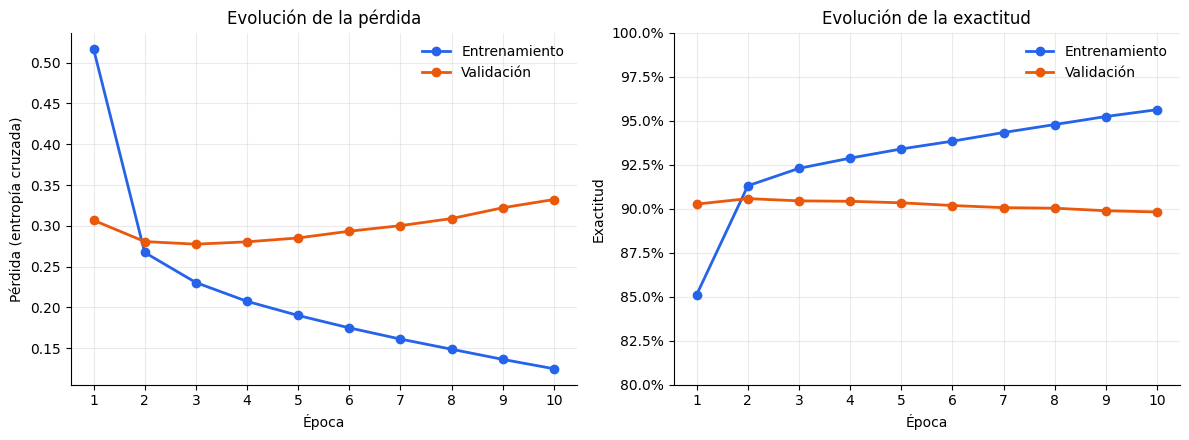

Pérdida final de entrenamiento: 0.1248
Pérdida final de validación: 0.3323
Exactitud final de entrenamiento: 95.63%
Exactitud final de validación: 89.82%


In [13]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

epochs_range = range(1, len(history["train_loss"]) + 1)

TRAIN_COLOR = "#2563EB"
VAL_COLOR = "#EA580C"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

#Evolución de la pérdida.
axes[0].plot(
    epochs_range, history["train_loss"],
    label="Entrenamiento", color=TRAIN_COLOR,
    linewidth=2, marker="o",
)
axes[0].plot(
    epochs_range, history["val_loss"],
    label="Validación", color=VAL_COLOR,
    linewidth=2, marker="o",
)
axes[0].set_title("Evolución de la pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida (entropía cruzada)")

#Evolución de la exactitud.
axes[1].plot(
    epochs_range, history["train_accuracy"],
    label="Entrenamiento", color=TRAIN_COLOR,
    linewidth=2, marker="o",
)
axes[1].plot(
    epochs_range, history["val_accuracy"],
    label="Validación", color=VAL_COLOR,
    linewidth=2, marker="o",
)
axes[1].set_title("Evolución de la exactitud")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Exactitud")
axes[1].set_ylim(0.80, 1.00)
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))

#Mantengo el formato de ambos gráficos.
for ax in axes:
    ax.set_xticks(list(epochs_range))
    ax.grid(True, alpha=0.25)
    ax.legend(frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

print(f"Pérdida final de entrenamiento: {history['train_loss'][-1]:.4f}")
print(f"Pérdida final de validación: {history['val_loss'][-1]:.4f}")
print(f"Exactitud final de entrenamiento: {history['train_accuracy'][-1]:.2%}")
print(f"Exactitud final de validación: {history['val_accuracy'][-1]:.2%}")

### Interpretación de los resultados

Durante las diez épocas, la pérdida de entrenamiento disminuyó
de 0.5170 a 0.1248 y la exactitud aumentó del 85,12 % al 95,63 %.

En validación, la pérdida descendió inicialmente y luego aumentó
de forma sostenida, finalizando en 0.3323. La exactitud final fue
del 89,82 %.

La mejora continua en entrenamiento no se trasladó a validación.
Esta diferencia indica sobreajuste durante la ejecución y muestra
que aumentar las épocas no garantiza un mejor desempeño en datos nuevos.

El pipeline permite registrar y visualizar este comportamiento.
Se conserva el modelo al finalizar las diez épocas y el archivo
de prueba permanece reservado para una evaluación posterior.

In [14]:
from importlib.metadata import version

#Consulto las versiones utilizadas.
for package in ["numpy", "pandas", "scikit-learn", "matplotlib", "torch"]:
    print(f"{package}=={version(package)}")

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
torch==2.11.0+cpu
